In [1]:
import os
import json
import pandas as pd


pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

In [2]:
base_path = "../results_global_threshold"

folders = {

    3: "test_eval_service_3",
    5: "test_eval_service_5",
    8: "test_eval_service_8",
    10: "test_eval_service_10"

}

In [3]:
data = {}

for k, folder_name in folders.items():

    folder_path = os.path.join(base_path, folder_name)
#     print(folder_path)

    data[k] = []

    for file_name in os.listdir(folder_path):

        if not file_name.endswith(".json"):
            continue

        if "_efficiency" in file_name:
            continue

        file_path = os.path.join(folder_path, file_name)
#         print(file_path)

        with open(file_path, "r") as f:
            rows = json.load(f)
#             print(rows)

        for row in rows:
            row = row.copy()
            row["source_file"] = file_name
            data[k].append(row)

    print(f"K={k}: loaded {len(data[k])} rows")

K=3: loaded 400 rows
K=5: loaded 600 rows
K=8: loaded 900 rows
K=10: loaded 1100 rows


In [11]:
df_k3_all_models = pd.DataFrame(data[3])
df_k5_all_models = pd.DataFrame(data[5])
df_k8_all_models = pd.DataFrame(data[8])
df_k10_all_models = pd.DataFrame(data[10])

model_name = "Qwen/Qwen3-Reranker-4B"

df_k3 = df_k3_all_models[
    df_k3_all_models["model_name"] == model_name
]

df_k5 = df_k5_all_models[
    df_k5_all_models["model_name"] == model_name
]

df_k8 = df_k8_all_models[
    df_k8_all_models["model_name"] == model_name
]

df_k10 = df_k10_all_models[
    df_k10_all_models["model_name"] == model_name
]

print("K=3:", df_k3.shape)
print("K=5:", df_k5.shape)
print("K=8:", df_k8.shape)
print("K=10:", df_k10.shape)

K=3: (400, 28)
K=5: (600, 28)
K=8: (900, 28)
K=10: (1100, 28)


In [12]:
def expand_scores_and_zscores(df):
    """
    Expand the nested `scores` and `zscores` dict columns
    into normal dataframe columns.
    """

    scores_df = (
        pd.json_normalize(df["scores"])
        .add_suffix("_score")
    )

    zscores_df = (
        pd.json_normalize(df["zscores"])
        .add_suffix("_zscore")
    )

    df_expanded = pd.concat(
        [
            df.reset_index(drop=True),
            scores_df.reset_index(drop=True),
            zscores_df.reset_index(drop=True),
        ],
        axis=1,
    )

    return df_expanded

In [13]:
df_k3 = expand_scores_and_zscores(df_k3)
df_k5 = expand_scores_and_zscores(df_k5)
df_k8 = expand_scores_and_zscores(df_k8)
df_k10 = expand_scores_and_zscores(df_k10)

In [14]:
def recall_summary(df):

    specialist_df = df[
        df["expected_service"] != "general"
    ]

    general_df = df[
        df["expected_service"] == "general"
    ]

    accuracy = df["is_correct"].mean()

    specialist_recall = (
        specialist_df["predicted_label"]
        == specialist_df["expected_service"]
    ).mean()

    general_recall = (
        general_df["predicted_label"]
        == "general"
    ).mean()

    print(
        f"Accuracy: {accuracy:.4f}"
    )

    print(
        f"Specialist Recall: "
        f"{specialist_recall:.4f}"
    )

    print(
        f"General Recall: "
        f"{general_recall:.4f}"
    )


In [15]:
recall_summary(df_k3)

Accuracy: 0.8650
Specialist Recall: 0.9867
General Recall: 0.5000


In [16]:
cm_k3 = pd.crosstab(
    df_k3["expected_service"],
    df_k3["predicted_label"]
)

cm_k3

predicted_label,abstract_algebra,anatomy,astronomy,general
expected_service,,,,
abstract_algebra,100,0,0,0
anatomy,0,99,0,1
astronomy,0,0,97,3
general,8,33,9,50


In [17]:
error_k3 = df_k3[ (df_k3["expected_service"] == "general") & (df_k3["predicted_label"] == "anatomy")]

In [18]:
error_k3[
    [
        "query",
        "expected_service",
        "predicted_label",

        "abstract_algebra_zscore",
        "anatomy_zscore",
        "astronomy_zscore",

        "top_zscore",
        "second_top_zscore",
        "zscore_margin",

        "std_score",

        "abstract_algebra_score",
        "anatomy_score",
        "astronomy_score",
    ]
]

,query,expected_service,predicted_label,abstract_algebra_zscore,anatomy_zscore,astronomy_zscore,top_zscore,second_top_zscore,zscore_margin,std_score,abstract_algebra_score,anatomy_score,astronomy_score
300,don't call me bill anymore - call me bob,general,anatomy,-0.7071,1.4142,-0.7071,1.4142,-0.7071,2.1213,0.3536,-12.4375,-11.68750,-12.4375
307,my capital one visa was taken without permission,general,anatomy,-0.8054,1.4094,-0.6040,1.4094,-0.6040,2.0134,0.3104,-12.5625,-11.87500,-12.5000
310,"I am traveling to Germany, Will I be able to use my card there?",general,anatomy,-0.9676,1.3770,-0.4094,1.3770,-0.4094,1.7864,0.5598,-13.2500,-11.93750,-12.9375
311,"If I feel someone has my card information, can I get a new card?",general,anatomy,-0.5682,1.4056,-0.8374,1.4056,-0.5682,1.9738,0.6966,-12.8125,-11.43750,-13.0000
313,Are there any fees for adding money with an international card?,general,anatomy,-1.1170,1.3096,-0.1926,1.3096,-0.1926,1.5022,0.5409,-13.6875,-12.37500,-13.1875
315,Why did I have to pay extra because I paid with card?,general,anatomy,-0.2673,1.3363,-1.0690,1.3363,-0.2673,1.6036,0.0780,-12.1875,-12.06250,-12.2500
325,"There is an incoming payment into my account, but it is deactivated. Will they still be processed?",general,anatomy,-1.1248,1.3048,-0.1800,1.3048,-0.1800,1.4848,0.4630,-13.0625,-11.93750,-12.6250
326,What will I be charged for a physical card?,general,anatomy,-0.1162,1.2787,-1.1625,1.2787,-0.1162,1.3949,0.5376,-12.1875,-11.43750,-12.7500
327,tell me what this song is called,general,anatomy,-0.5620,1.4049,-0.8429,1.4049,-0.5620,1.9669,0.2224,-11.1875,-10.75000,-11.2500
332,play the next song please,general,anatomy,-0.5793,1.4069,-0.8276,1.4069,-0.5793,1.9862,0.2517,-11.2500,-10.75000,-11.3125


# K5

In [19]:
recall_summary(df_k5)

Accuracy: 0.8683
Specialist Recall: 0.8920
General Recall: 0.7500


In [20]:
cm_k5 = pd.crosstab(
    df_k5["expected_service"],
    df_k5["predicted_label"]
)
cm_k5

predicted_label,abstract_algebra,anatomy,astronomy,business_ethics,college_computer_science,general
expected_service,,,,,,
abstract_algebra,94,0,0,0,0,6
anatomy,0,97,0,0,0,3
astronomy,0,0,96,0,0,4
business_ethics,0,0,0,88,0,12
college_computer_science,1,0,0,0,71,28
general,3,9,3,4,6,75


In [21]:
error_k5 = df_k5[ (df_k5["expected_service"] == "general") & (df_k5["predicted_label"] == "anatomy")]

In [22]:
error_k5[
    [
        "query",
        "expected_service",
        "predicted_label",

        "abstract_algebra_zscore",
        "anatomy_zscore",
        "astronomy_zscore",
        "business_ethics_zscore",
        "college_computer_science_zscore",

#         "top_zscore",
#         "second_top_zscore",
        "zscore_margin",

        "std_score",

        "abstract_algebra_score",
        "anatomy_score",
        "astronomy_score",
        "business_ethics_score",
        "college_computer_science_score",
    ]
]

,query,expected_service,predicted_label,abstract_algebra_zscore,anatomy_zscore,astronomy_zscore,business_ethics_zscore,college_computer_science_zscore,zscore_margin,std_score,abstract_algebra_score,anatomy_score,astronomy_score,business_ethics_score,college_computer_science_score
510,"I am traveling to Germany, Will I be able to use my card there?",general,anatomy,-0.3289,1.8637,0.1096,-0.9867,-0.6578,1.7541,0.5701,-13.2500,-12.00000,-13.0000,-13.6250,-13.4375
511,"If I feel someone has my card information, can I get a new card?",general,anatomy,-0.6589,1.8119,-1.0118,-0.4236,0.2824,1.5295,0.5312,-12.8750,-11.56250,-13.0625,-12.7500,-12.3750
525,"There is an incoming payment into my account, but it is deactivated. Will they still be processed?",general,anatomy,-1.2143,1.6429,0.2143,-0.8571,0.2143,1.4286,0.3500,-13.0625,-12.06250,-12.5625,-12.9375,-12.5625
557,can i redeem my points by transferring them to someone as a gift,general,anatomy,0.1108,1.7723,-0.4431,-0.1662,-1.2739,1.6615,0.2257,-11.6875,-11.31250,-11.8125,-11.7500,-12.0000
558,I understand that this is extremely late. After going over my transactions for the last couple of months I noticed a large charge that I'm sure I did not make. Is there anyway I can still dispute this?,general,anatomy,-1.5026,1.6278,-0.0417,0.1670,-0.2504,1.4608,0.2995,-13.1250,-12.18750,-12.6875,-12.6250,-12.7500
559,what is the amount of blood needed to stay alive,general,anatomy,-0.1726,1.7151,0.3668,-1.1434,-0.7659,1.3483,1.1588,-11.6250,-9.43750,-11.0000,-12.7500,-12.3125
567,what's the french word you use for potato,general,anatomy,-0.2722,1.6330,0.0000,-1.4969,0.1361,1.4969,0.4593,-13.1250,-12.25000,-13.0000,-13.6875,-12.9375
568,say again please,general,anatomy,-0.9263,1.8089,-0.9263,0.0948,-0.0511,1.7141,0.8569,-10.0000,-7.65625,-10.0000,-9.1250,-9.2500
596,is it okay to use butter instead of margarine,general,anatomy,-0.3217,1.7463,0.3676,-1.1259,-0.6664,1.3787,0.5440,-12.6250,-11.50000,-12.2500,-13.0625,-12.8125


# K8

In [23]:
recall_summary(df_k8)

Accuracy: 0.7933
Specialist Recall: 0.7913
General Recall: 0.8100


In [24]:
cm_k8 = pd.crosstab(
    df_k8["expected_service"],
    df_k8["predicted_label"]
)

cm_k8

predicted_label,abstract_algebra,anatomy,astronomy,business_ethics,college_computer_science,general,high_school_chemistry,high_school_geography,jurisprudence
expected_service,,,,,,,,,
abstract_algebra,93,0,0,0,0,7,0,0,0
anatomy,0,95,0,0,0,5,0,0,0
astronomy,0,0,88,0,0,12,0,0,0
business_ethics,0,0,0,58,0,40,0,0,2
college_computer_science,1,0,0,0,74,25,0,0,0
general,1,3,3,0,3,81,0,0,9
high_school_chemistry,0,0,0,0,0,13,87,0,0
high_school_geography,1,0,0,2,0,42,0,47,8
jurisprudence,0,0,0,0,0,9,0,0,91


In [35]:
error_k8 = df_k8[ (df_k8["expected_service"] == "abstract_algebra") & (df_k8["predicted_label"] == "general")]

In [36]:
error_k8[
    [
        "query",
        "expected_service",
        "predicted_label",

        "abstract_algebra_zscore",
        "anatomy_zscore",
        "astronomy_zscore",
        "business_ethics_zscore",
        "college_computer_science_zscore",
        "high_school_chemistry_zscore",
        "high_school_geography_zscore",
        "jurisprudence_zscore",

#         "top_zscore",
#         "second_top_zscore",
        "zscore_margin",

        "std_score",

        "abstract_algebra_score",
        "anatomy_score",
        "astronomy_score",
        "business_ethics_score",
        "college_computer_science_score",
        "high_school_chemistry_score",
        "high_school_geography_score",
        "jurisprudence_score",
    ]
]

,query,expected_service,predicted_label,abstract_algebra_zscore,anatomy_zscore,astronomy_zscore,business_ethics_zscore,college_computer_science_zscore,high_school_chemistry_zscore,high_school_geography_zscore,jurisprudence_zscore,zscore_margin,std_score,abstract_algebra_score,anatomy_score,astronomy_score,business_ethics_score,college_computer_science_score,high_school_chemistry_score,high_school_geography_score,jurisprudence_score
4,"Let A and B be sets, f: A -> B and g: B -> A be functions such that for all a \in A, g(f(a)) = a. Statement 1 | The function f must necessarily be injective. Statement 2 | The function f must necessarily be surjective.",abstract_algebra,general,1.9763,-0.1277,-0.3482,-0.8291,1.2749,-0.3482,-1.1497,-0.4484,0.7014,3.1190,-3.62500,-10.18750,-10.87500,-12.3750,-5.81250,-10.8750,-13.3750,-11.1875
6,"Statement 1 | Any set of two vectors in R^2 is linearly independent. Statement 2 | If V = span(v1, ... , vk) and {v1, ... , vk} are linearly independent, then dim(V) = k.",abstract_algebra,general,1.9713,-0.2056,-0.0847,-0.9796,1.0764,-0.0605,-1.3424,-0.3749,0.8949,2.5839,-5.75000,-11.37500,-11.06250,-13.3750,-8.06250,-11.0000,-14.3125,-11.8125
30,"If A = {1, 2, 3} then relation S = {(1, 1), (2, 2)} is",abstract_algebra,general,1.8961,-0.5989,-0.3258,-0.7975,1.4492,-0.2265,-0.9961,-0.4003,0.4469,2.5176,-6.09375,-12.37500,-11.68750,-12.8750,-7.21875,-11.4375,-13.3750,-11.8750
41,"Statement 1 | If T: V -> W is a linear transformation and dim(V ) < dim(W) < 1, then T must be injective. Statement 2 | Let dim(V) = n and suppose that T: V -> V is linear. If T is injective, then it is a bijection.",abstract_algebra,general,2.1067,-0.1998,-0.3597,-0.7936,1.0334,-0.0628,-1.1818,-0.5424,1.0733,2.7368,-5.00000,-11.31250,-11.75000,-12.9375,-7.93750,-10.9375,-14.0000,-12.2500
77,"Statement 1 | In a finite dimensional vector space every linearly independent set of vectors is contained in a basis. Statement 2 | If B_1 and B_2 are bases for the same vector space, then |B_1| = |B_2|.",abstract_algebra,general,2.0519,-0.2966,-0.2722,-0.9327,1.1712,-0.1743,-1.0550,-0.4923,0.8807,2.5548,-6.37500,-12.37500,-12.31250,-14.0000,-8.62500,-12.0625,-14.3125,-12.8750
81,"Let A and B be sets, f: A -> B and g: B -> A be functions such that for all a \in A, g(f(a)) = a. Statement 1 | The function g must necessarily be injective. Statement 2 | The function g must necessarily be surjective.",abstract_algebra,general,2.0235,-0.1389,-0.3769,-0.8134,1.2300,-0.3571,-1.1109,-0.4563,0.7935,3.1505,-3.43750,-10.25000,-11.00000,-12.3750,-5.93750,-10.9375,-13.3125,-11.2500
98,Which of the following statements is true?,abstract_algebra,general,1.4116,0.4970,-0.1392,-0.1789,-0.0199,0.2982,-2.3261,0.4573,0.9146,0.7859,-5.81250,-6.53125,-7.03125,-7.0625,-6.93750,-6.6875,-8.7500,-6.5625


# K10

In [27]:
recall_summary(df_k10)

Accuracy: 0.7373
Specialist Recall: 0.7240
General Recall: 0.8700


In [28]:
cm_k10 = pd.crosstab(
    df_k10["expected_service"],
    df_k10["predicted_label"]
)

cm_k10

predicted_label,abstract_algebra,anatomy,astronomy,business_ethics,college_computer_science,formal_logic,general,high_school_chemistry,high_school_geography,jurisprudence,world_religions
expected_service,,,,,,,,,,,
abstract_algebra,70,0,0,0,0,1,29,0,0,0,0
anatomy,0,96,0,0,0,0,4,0,0,0,0
astronomy,0,0,89,0,0,1,10,0,0,0,0
business_ethics,0,0,0,59,0,1,39,0,0,1,0
college_computer_science,1,0,0,0,59,0,40,0,0,0,0
formal_logic,0,0,0,0,0,92,8,0,0,0,0
general,0,2,3,0,2,0,87,0,0,6,0
high_school_chemistry,0,0,0,0,0,0,14,86,0,0,0
high_school_geography,0,0,1,3,0,0,47,0,36,4,9


In [29]:
error_k10 = df_k10[ (df_k10["expected_service"] == "general") & (df_k10["predicted_label"] == "astronomy")]

In [30]:
error_k10[
    [
        "query",
        "expected_service",
        "predicted_label",

        "abstract_algebra_zscore",
        "anatomy_zscore",
        "astronomy_zscore",
        "business_ethics_zscore",
        "college_computer_science_zscore",
        "formal_logic_zscore",
        "high_school_chemistry_zscore",
        "high_school_geography_zscore",
        "jurisprudence_zscore",
        "world_religions_zscore",

        "top_zscore",
        "second_top_zscore",
        "zscore_margin",

        "std_score",

        "abstract_algebra_score",
        "anatomy_score",
        "astronomy_score",
        "business_ethics_score",
        "college_computer_science_score",
        "formal_logic_score",
        "high_school_chemistry_score",
        "high_school_geography_score",
        "jurisprudence_score",
        "world_religions_score",
    ]
]

,query,expected_service,predicted_label,abstract_algebra_zscore,anatomy_zscore,astronomy_zscore,business_ethics_zscore,college_computer_science_zscore,formal_logic_zscore,high_school_chemistry_zscore,high_school_geography_zscore,jurisprudence_zscore,world_religions_zscore,top_zscore,second_top_zscore,zscore_margin,std_score,abstract_algebra_score,anatomy_score,astronomy_score,business_ethics_score,college_computer_science_score,formal_logic_score,high_school_chemistry_score,high_school_geography_score,jurisprudence_score,world_religions_score
1019,How long will it take to arrive?,general,astronomy,0.0496,0.5454,2.5287,-0.8594,0.2149,-0.4462,-0.6941,-0.3636,-1.2726,0.2975,2.5287,0.5454,1.9833,0.7563,-11.2500,-10.8750,-9.37500,-11.9375,-11.125,-11.6250,-11.8125,-11.5625,-12.2500,-11.0625
1029,what is the weather doing now,general,astronomy,0.4117,0.8423,2.3763,-1.1491,-0.0727,-0.6647,-0.0727,0.0350,-1.2029,-0.5032,2.3763,0.8423,1.5340,1.1612,-10.0625,-9.5625,-7.78125,-11.8750,-10.625,-11.3125,-10.6250,-10.5000,-11.9375,-11.1250
1093,is socket converter required in france,general,astronomy,0.4041,0.4041,2.4945,-0.5714,0.5435,-0.5714,-0.2927,-1.2682,-0.2927,-0.8501,2.4945,0.5435,1.9510,0.4485,-12.9375,-12.9375,-12.00000,-13.3750,-12.875,-13.3750,-13.2500,-13.6875,-13.2500,-13.5000


### Analyse 1: general questions vs specialist questions

# K3

### Create binary expected

In [5]:
def get_binary_label(expected_service):
    if expected_service == "general":
        return "general"
    else:
        return "specialist"


df_k3["binary_expected"] = df_k3["expected_service"].apply(get_binary_label)

In [6]:
df_k3["binary_expected"].value_counts()

general       25
specialist    15
Name: binary_expected, dtype: int64

### Unpack scores and zscores and concat with df_k3

In [7]:
scores_k3 = pd.json_normalize(df_k3["scores"]).add_suffix("_score")
zscores_k3 = pd.json_normalize(df_k3["zscores"]).add_suffix("_zscore")

In [8]:
df_k3 = pd.concat(
    [
        df_k3.reset_index(drop=True),
        scores_k3.reset_index(drop=True),
        zscores_k3.reset_index(drop=True)
    ],
    axis=1
)

In [9]:
df_k3.columns.tolist()

['routing_method',
 'query',
 'raw_response',
 'predicted_label',
 'top_candidate',
 'model_name',
 'latency_ms',
 'prompt_tokens',
 'completion_tokens',
 'total_tokens',
 'max_score',
 'margin',
 'margin_ratio',
 'normalized_margin',
 'mean_score',
 'std_score',
 'top_zscore',
 'second_top_zscore',
 'zscore_margin',
 'scores',
 'zscores',
 'query_id',
 'expected_service',
 'is_correct',
 'error',
 'specialist_service_count',
 'total_service_count',
 'source_file',
 'binary_expected',
 'abstract_algebra_score',
 'anatomy_score',
 'astronomy_score',
 'abstract_algebra_zscore',
 'anatomy_zscore',
 'astronomy_zscore']

In [74]:
df_k3[
    [
        "query_id",
        "expected_service",
        "binary_expected",
        "predicted_label",
        "max_score",
        "margin",
        'mean_score',
        "std_score",
        "zscore_margin",
        "anatomy_score",
        "astronomy_score",
        "abstract_algebra_score",
        
        "top_zscore",
        "abstract_algebra_zscore",
        "anatomy_zscore",
        "astronomy_zscore"
                
    ]
]

,query_id,expected_service,binary_expected,predicted_label,max_score,margin,mean_score,std_score,zscore_margin,anatomy_score,astronomy_score,abstract_algebra_score,top_zscore,abstract_algebra_zscore,anatomy_zscore,astronomy_zscore
0,0,abstract_algebra,specialist,abstract_algebra,-4.3750,8.3125,-9.9792,3.9635,2.0972,-12.87500,-12.68750,-4.3750,1.4139,1.4139,-0.7306,-0.6833
1,1,abstract_algebra,specialist,abstract_algebra,7.2500,18.8125,-5.5000,9.0192,2.0858,-11.56250,-12.18750,7.2500,1.4136,1.4136,-0.6722,-0.7415
2,2,abstract_algebra,specialist,abstract_algebra,5.9375,17.0625,-5.5625,8.1332,2.0979,-11.12500,-11.50000,5.9375,1.4140,1.4140,-0.6839,-0.7300
3,3,abstract_algebra,specialist,abstract_algebra,3.6875,13.2500,-5.7083,6.6795,1.9837,-9.56250,-11.25000,3.6875,1.4067,1.4067,-0.5770,-0.8297
4,4,abstract_algebra,specialist,abstract_algebra,-4.7500,7.9375,-10.2500,3.8974,2.0366,-12.68750,-13.31250,-4.7500,1.4112,1.4112,-0.6254,-0.7858
5,5,anatomy,specialist,anatomy,-5.5000,5.8125,-9.9375,3.2125,1.8093,-5.50000,-11.31250,-13.0000,1.3813,-0.9533,1.3813,-0.4280
6,6,anatomy,specialist,anatomy,-6.1875,7.3125,-11.1875,3.5388,2.0664,-6.18750,-13.50000,-13.8750,1.4129,-0.7594,1.4129,-0.6535
7,7,anatomy,specialist,anatomy,-6.1562,5.1562,-9.6146,2.4455,2.1084,-6.15625,-11.37500,-11.3125,1.4141,-0.6943,1.4141,-0.7198
8,8,anatomy,specialist,anatomy,-8.1250,3.5000,-10.6250,1.7795,1.9669,-8.12500,-12.12500,-11.6250,1.4049,-0.5620,1.4049,-0.8429
9,9,anatomy,specialist,anatomy,-7.0938,5.4062,-11.0521,2.8324,1.9087,-7.09375,-12.50000,-13.5625,1.3975,-0.8863,1.3975,-0.5112


In [11]:
df_k3.groupby("binary_expected")[["margin"]].describe()

margin                                                        
                 count     mean       std  min     25%     50%    75%      max
binary_expected                                                               
general           25.0  0.56500  0.372159  0.0  0.3125  0.5625  0.750   1.4375
specialist        15.0  7.75416  4.786137  3.5  4.8906  5.4375  8.125  18.8125

In [12]:
df_k3.groupby("binary_expected")[["top_zscore"]].describe()

top_zscore                                              \
                     count      mean       std     min     25%     50%   
binary_expected                                                          
general               25.0  1.206440  0.232971  0.7071  1.0933  1.3363   
specialist            15.0  1.403073  0.011042  1.3813  1.3941  1.4067   

                                  
                     75%     max  
binary_expected                   
general          1.37280  1.4142  
specialist       1.41325  1.4141

In [13]:
df_k3.groupby("binary_expected")[["max_score"]].describe()

max_score                                                   \
                    count       mean       std      min       25%      50%   
binary_expected                                                              
general              25.0 -11.067500  0.782482 -12.5625 -11.62500 -11.0000   
specialist           15.0  -4.120833  5.215607  -8.2500  -7.45315  -6.1562   

                                
                     75%   max  
binary_expected                 
general         -10.7500 -9.25  
specialist       -4.5625  7.25

In [14]:
df_k3.groupby("binary_expected")[["zscore_margin"]].describe()

zscore_margin                                              \
                        count      mean       std     min     25%     50%   
binary_expected                                                             
general                  25.0  1.288988  0.661899  0.0000  0.8631  1.6036   
specialist               15.0  1.976613  0.103115  1.8093  1.8855  1.9837   

                                 
                    75%     max  
binary_expected                  
general          1.7650  2.1213  
specialist       2.0761  2.1084

In [15]:
# df_k3[
#     (df_k3["zscore_margin"] >= 1.7650)
#     &
#     (df_k3["zscore_margin"] <= 1.8855)
# ][
#     [
#         "query_id",
#         "binary_expected",
#         "expected_service",
#         "predicted_label",
#         "zscore_margin",
        
        
#         "anatomy_score",
#         "astronomy_score",
#         "abstract_algebra_score",
        
#         "top_zscore",
#         "abstract_algebra_zscore",
#         "anatomy_zscore",
#         "astronomy_zscore"
        
#     ]
# ].sort_values("zscore_margin")

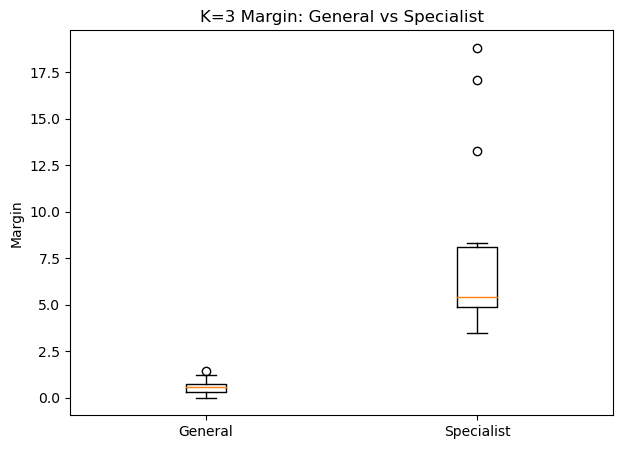

In [16]:
import matplotlib.pyplot as plt

general = df_k3.loc[df_k3["binary_expected"] == "general", "margin"]
specialist = df_k3.loc[df_k3["binary_expected"] == "specialist", "margin"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [general, specialist],
    labels=["General", "Specialist"]
)

plt.ylabel("Margin")
plt.title("K=3 Margin: General vs Specialist")
plt.show()

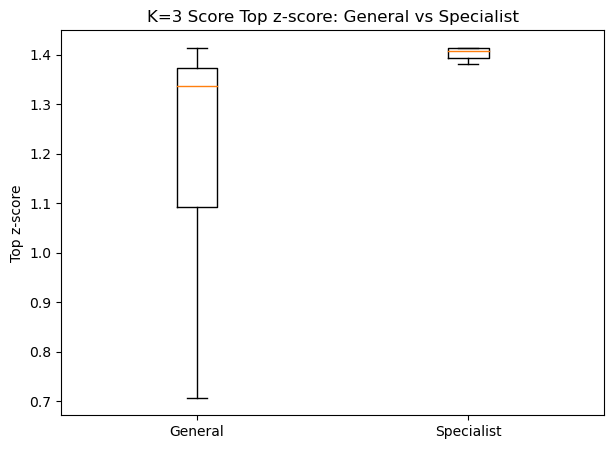

In [17]:
import matplotlib.pyplot as plt

general = df_k3.loc[df_k3["binary_expected"] == "general", "top_zscore"]
specialist = df_k3.loc[df_k3["binary_expected"] == "specialist", "top_zscore"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [general, specialist],
    labels=["General", "Specialist"]
)

plt.ylabel("Top z-score")
plt.title("K=3 Score Top z-score: General vs Specialist")

plt.show()

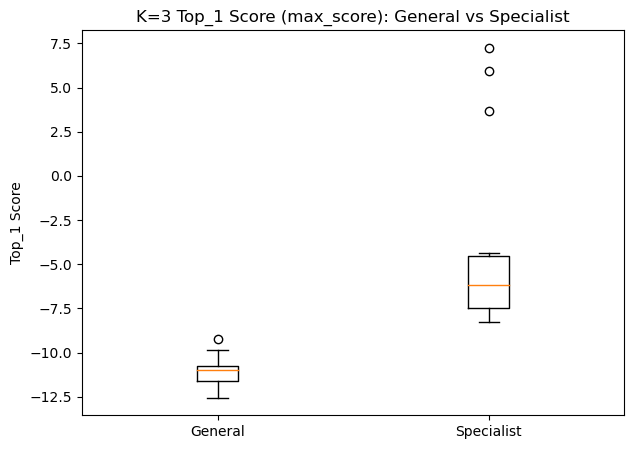

In [18]:
import matplotlib.pyplot as plt

general = df_k3.loc[df_k3["binary_expected"] == "general", "max_score"]
specialist = df_k3.loc[df_k3["binary_expected"] == "specialist", "max_score"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [general, specialist],
    labels=["General", "Specialist"]
)

plt.ylabel("Top_1 Score")
plt.title("K=3 Top_1 Score (max_score): General vs Specialist")

plt.show()

# K5

In [19]:
def get_binary_label(expected_service):
    if expected_service == "general":
        return "general"
    else:
        return "specialist"


df_k5["binary_expected"] = df_k5["expected_service"].apply(get_binary_label)

In [20]:
df_k5["binary_expected"].value_counts()

specialist    25
general       25
Name: binary_expected, dtype: int64

In [21]:
scores_k5 = pd.json_normalize(df_k5["scores"]).add_suffix("_score")
zscores_k5 = pd.json_normalize(df_k5["zscores"]).add_suffix("_zscore")

In [22]:
df_k5 = pd.concat(
    [
        df_k5.reset_index(drop=True),
        scores_k5.reset_index(drop=True),
        zscores_k5.reset_index(drop=True)
    ],
    axis=1
)

In [23]:
df_k5.columns.tolist()

['routing_method',
 'query',
 'raw_response',
 'predicted_label',
 'top_candidate',
 'model_name',
 'latency_ms',
 'prompt_tokens',
 'completion_tokens',
 'total_tokens',
 'max_score',
 'margin',
 'margin_ratio',
 'normalized_margin',
 'mean_score',
 'std_score',
 'top_zscore',
 'second_top_zscore',
 'zscore_margin',
 'scores',
 'zscores',
 'query_id',
 'expected_service',
 'is_correct',
 'error',
 'specialist_service_count',
 'total_service_count',
 'source_file',
 'binary_expected',
 'abstract_algebra_score',
 'anatomy_score',
 'astronomy_score',
 'business_ethics_score',
 'college_computer_science_score',
 'abstract_algebra_zscore',
 'anatomy_zscore',
 'astronomy_zscore',
 'business_ethics_zscore',
 'college_computer_science_zscore']

In [24]:
df_k5[
    [
        "query_id",
        "expected_service",
        "binary_expected",
        "predicted_label",
        "max_score",
        "margin",
        "anatomy_score",
        "astronomy_score",
        "abstract_algebra_score",
        "business_ethics_score",
        "college_computer_science_score",
        
        "top_zscore",
        "abstract_algebra_zscore",
        "anatomy_zscore",
        "astronomy_zscore",
        "business_ethics_zscore",
        "college_computer_science_zscore"
                
    ]
]

,query_id,expected_service,binary_expected,predicted_label,max_score,margin,anatomy_score,astronomy_score,abstract_algebra_score,business_ethics_score,college_computer_science_score,top_zscore,abstract_algebra_zscore,anatomy_zscore,astronomy_zscore,business_ethics_zscore,college_computer_science_zscore
0,0,abstract_algebra,specialist,abstract_algebra,-4.4375,6.3125,-12.87500,-12.75000,-4.4375,-14.37500,-10.75000,1.8882,1.8882,-0.5257,-0.4899,-0.9548,0.0822
1,1,abstract_algebra,specialist,abstract_algebra,7.1250,15.7500,-11.62500,-12.31250,7.1250,-12.81250,-8.62500,1.9624,1.9624,-0.5279,-0.6193,-0.6857,-0.1295
2,2,abstract_algebra,specialist,abstract_algebra,6.0000,13.7812,-11.25000,-11.62500,6.0000,-12.68750,-7.78125,1.9428,1.9428,-0.5454,-0.5995,-0.7528,-0.0451
3,3,abstract_algebra,specialist,abstract_algebra,3.6250,10.0000,-9.62500,-11.37500,3.6250,-12.37500,-6.37500,1.8721,1.8721,-0.4141,-0.7160,-0.8886,0.1467
4,4,abstract_algebra,specialist,abstract_algebra,-4.7500,5.3125,-12.87500,-13.43750,-4.7500,-14.81250,-10.06250,1.8028,1.8028,-0.4726,-0.6301,-1.0151,0.3150
5,5,anatomy,specialist,anatomy,-5.5625,5.8125,-5.56250,-11.37500,-12.9375,-13.81250,-13.12500,1.9284,-0.5237,1.9284,-0.0042,-0.8146,-0.5860
6,6,anatomy,specialist,anatomy,-6.1875,7.4375,-6.18750,-13.62500,-14.0000,-14.00000,-13.87500,1.9980,-0.5401,1.9980,-0.4183,-0.5401,-0.4995
7,7,anatomy,specialist,anatomy,-6.0938,5.2812,-6.09375,-11.56250,-11.3750,-13.00000,-11.87500,1.9445,-0.2463,1.9445,-0.3241,-0.9204,-0.4537
8,8,anatomy,specialist,anatomy,-8.0625,3.5625,-8.06250,-12.12500,-11.6250,-14.12500,-12.31250,1.8092,0.0126,1.8092,-0.2395,-1.2481,-0.3341
9,9,anatomy,specialist,anatomy,-7.2188,5.1562,-7.21875,-12.37500,-13.6250,-14.31250,-13.75000,1.9397,-0.5270,1.9397,-0.0457,-0.7918,-0.5752


In [25]:
df_k5.groupby("binary_expected")[["margin"]].describe()

margin                                                    \
                 count     mean       std     min    25%     50%     75%   
binary_expected                                                            
general           25.0  0.42750  0.339308  0.0625  0.125  0.3125  0.6875   
specialist        25.0  5.95124  3.153440  2.2812  4.000  5.2812  6.3125   

                        
                   max  
binary_expected         
general           1.25  
specialist       15.75

In [26]:
df_k5.groupby("binary_expected")[["top_zscore"]].describe()

top_zscore                                              \
                     count      mean       std     min     25%     50%   
binary_expected                                                          
general               25.0  1.398416  0.284897  0.9863  1.1691  1.2811   
specialist            25.0  1.900060  0.075361  1.7808  1.8092  1.9284   

                                 
                    75%     max  
binary_expected                  
general          1.6418  1.8927  
specialist       1.9636  1.9980

In [27]:
df_k5.groupby("binary_expected")[["max_score"]].describe()

max_score                                                  \
                    count       mean       std      min      25%      50%   
binary_expected                                                             
general              25.0 -10.967500  0.816122 -12.5000 -11.6875 -10.9375   
specialist           25.0  -5.122508  4.330862  -8.3125  -7.6250  -6.8750   

                                 
                    75%     max  
binary_expected                  
general         -10.375 -9.1875  
specialist       -4.750  7.1250

In [28]:
df_k5.groupby("binary_expected")[["zscore_margin"]].describe()

zscore_margin                                              \
                        count      mean       std     min     25%     50%   
binary_expected                                                             
general                  25.0  0.778108  0.604907  0.1286  0.3046  0.5812   
specialist               25.0  1.961632  0.292741  1.4705  1.7966  1.9879   

                                
                   75%     max  
binary_expected                 
general          1.305  1.9277  
specialist       2.126  2.4163

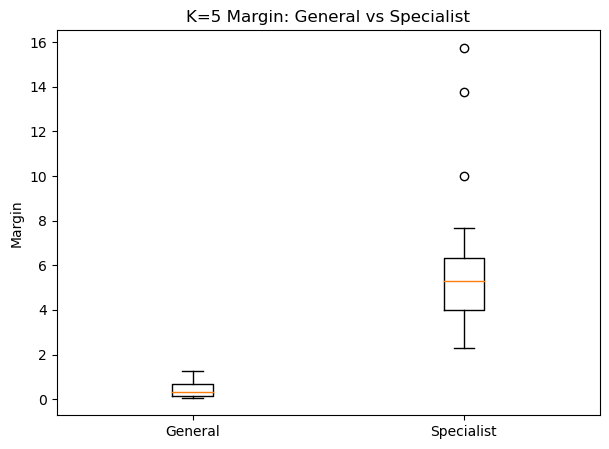

In [29]:
import matplotlib.pyplot as plt

general = df_k5.loc[df_k5["binary_expected"] == "general", "margin"]
specialist = df_k5.loc[df_k5["binary_expected"] == "specialist", "margin"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [general, specialist],
    labels=["General", "Specialist"]
)

plt.ylabel("Margin")
plt.title("K=5 Margin: General vs Specialist")
plt.show()

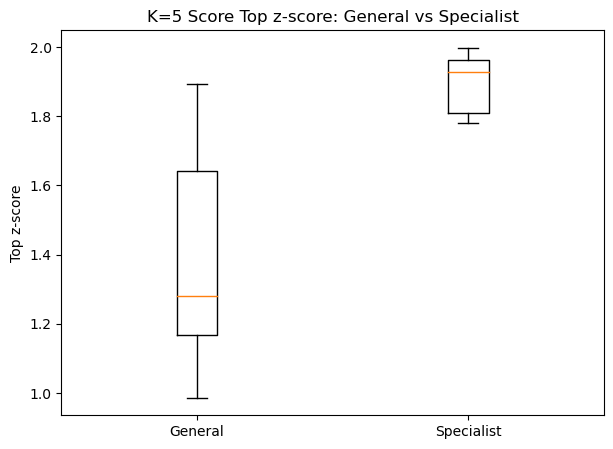

In [30]:
import matplotlib.pyplot as plt

general = df_k5.loc[df_k5["binary_expected"] == "general", "top_zscore"]
specialist = df_k5.loc[df_k5["binary_expected"] == "specialist", "top_zscore"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [general, specialist],
    labels=["General", "Specialist"]
)

plt.ylabel("Top z-score")
plt.title("K=5 Score Top z-score: General vs Specialist")

plt.show()

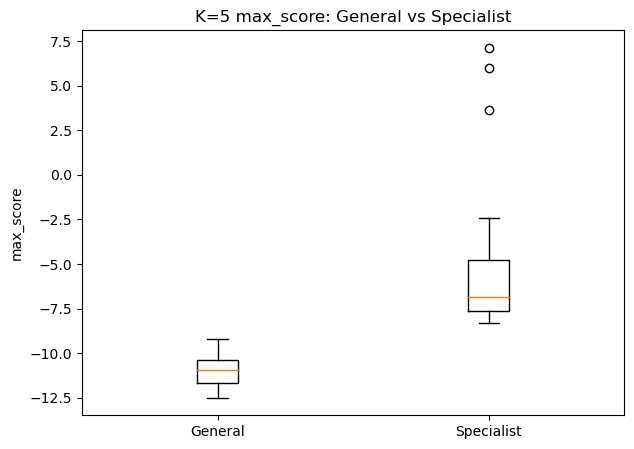

In [31]:
import matplotlib.pyplot as plt

general = df_k5.loc[df_k5["binary_expected"] == "general", "max_score"]
specialist = df_k5.loc[df_k5["binary_expected"] == "specialist", "max_score"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [general, specialist],
    labels=["General", "Specialist"]
)

plt.ylabel("max_score")
plt.title("K=5 max_score: General vs Specialist")

plt.show()

# K8

In [32]:
def get_binary_label(expected_service):
    if expected_service == "general":
        return "general"
    else:
        return "specialist"


df_k8["binary_expected"] = df_k8["expected_service"].apply(get_binary_label)

In [33]:
df_k8["binary_expected"].value_counts()

specialist    40
general       25
Name: binary_expected, dtype: int64

In [34]:
scores_k8 = pd.json_normalize(df_k8["scores"]).add_suffix("_score")
zscores_k8 = pd.json_normalize(df_k8["zscores"]).add_suffix("_zscore")

df_k8 = pd.concat(
    [
        df_k8.reset_index(drop=True),
        scores_k8.reset_index(drop=True),
        zscores_k8.reset_index(drop=True)
    ],
    axis=1
)

In [35]:
df_k8.columns.tolist()

['routing_method',
 'query',
 'raw_response',
 'predicted_label',
 'top_candidate',
 'model_name',
 'latency_ms',
 'prompt_tokens',
 'completion_tokens',
 'total_tokens',
 'max_score',
 'margin',
 'margin_ratio',
 'normalized_margin',
 'mean_score',
 'std_score',
 'top_zscore',
 'second_top_zscore',
 'zscore_margin',
 'scores',
 'zscores',
 'query_id',
 'expected_service',
 'is_correct',
 'error',
 'specialist_service_count',
 'total_service_count',
 'source_file',
 'binary_expected',
 'abstract_algebra_score',
 'anatomy_score',
 'astronomy_score',
 'business_ethics_score',
 'college_computer_science_score',
 'high_school_chemistry_score',
 'high_school_geography_score',
 'jurisprudence_score',
 'abstract_algebra_zscore',
 'anatomy_zscore',
 'astronomy_zscore',
 'business_ethics_zscore',
 'college_computer_science_zscore',
 'high_school_chemistry_zscore',
 'high_school_geography_zscore',
 'jurisprudence_zscore']

In [36]:
# see full height

pd.set_option("display.max_rows", None)

In [37]:
df_k8[
    [
        "query_id",
        "expected_service",
        "binary_expected",
        "predicted_label",

        "max_score",
        "margin",

        "abstract_algebra_score",
        "anatomy_score",
        "astronomy_score",
        "business_ethics_score",
        "college_computer_science_score",
        "high_school_chemistry_score",
        "high_school_geography_score",
        "jurisprudence_score",

        "top_zscore",

        "abstract_algebra_zscore",
        "anatomy_zscore",
        "astronomy_zscore",
        "business_ethics_zscore",
        "college_computer_science_zscore",
        "high_school_chemistry_zscore",
        "high_school_geography_zscore",
        "jurisprudence_zscore",
    ]
]

,query_id,expected_service,binary_expected,predicted_label,max_score,margin,abstract_algebra_score,anatomy_score,astronomy_score,business_ethics_score,...,jurisprudence_score,top_zscore,abstract_algebra_zscore,anatomy_zscore,astronomy_zscore,business_ethics_zscore,college_computer_science_zscore,high_school_chemistry_zscore,high_school_geography_zscore,jurisprudence_zscore
0,0,abstract_algebra,specialist,abstract_algebra,-4.3750,6.2500,-4.3750,-12.87500,-12.68750,-14.37500,...,-13.00000,2.4423,2.4423,-0.3256,-0.2646,-0.8141,0.4070,-0.1425,-0.9362,-0.3663
1,1,abstract_algebra,specialist,abstract_algebra,7.2500,15.8750,7.2500,-11.56250,-12.18750,-12.75000,...,-11.62500,2.5828,2.5828,-0.3550,-0.4526,-0.5405,0.1037,-0.2770,-0.6966,-0.3648
2,2,abstract_algebra,specialist,abstract_algebra,5.9375,13.7500,5.9375,-11.12500,-11.50000,-12.62500,...,-11.75000,2.5475,2.5475,-0.3353,-0.3986,-0.5887,0.2244,-0.2402,-0.7682,-0.4409
3,3,abstract_algebra,specialist,abstract_algebra,3.6875,9.9375,3.6875,-9.56250,-11.25000,-12.25000,...,-10.25000,2.4216,2.4216,-0.1517,-0.4795,-0.6737,0.4916,-0.3217,-1.0014,-0.2852
4,4,abstract_algebra,specialist,abstract_algebra,-4.7500,5.2500,-4.7500,-12.87500,-13.31250,-14.81250,...,-13.00000,2.3666,2.3666,-0.2885,-0.4314,-0.9216,0.6510,-0.2068,-0.8399,-0.3293
5,5,anatomy,specialist,anatomy,-5.5625,5.8125,-12.8750,-5.56250,-11.37500,-13.81250,...,-13.18750,2.5416,-0.3420,2.5416,0.2495,-0.7116,-0.4405,-0.1941,-0.6377,-0.4652
6,6,anatomy,specialist,anatomy,-6.1562,6.4062,-13.9375,-6.15625,-13.56250,-14.06250,...,-13.81250,2.6057,-0.4858,2.6057,-0.3368,-0.5354,-0.4361,0.0605,-0.4361,-0.4361
7,7,anatomy,specialist,anatomy,-6.1250,5.1875,-11.3125,-6.12500,-11.56250,-13.00000,...,-12.62500,2.5135,0.1121,2.5135,-0.0036,-0.6691,-0.2061,-0.3508,-0.9005,-0.4955
8,8,anatomy,specialist,anatomy,-8.1250,3.5000,-11.6250,-8.12500,-12.12500,-14.18750,...,-12.50000,2.3831,0.2773,2.3831,-0.0235,-1.2644,-0.1739,-0.2491,-0.7003,-0.2491
9,9,anatomy,specialist,anatomy,-7.2188,4.8438,-13.4375,-7.21875,-12.50000,-14.31250,...,-13.93750,2.5009,-0.3779,2.5009,0.0561,-0.7830,-0.4937,0.2586,-0.5515,-0.6094


In [38]:
df_k8.groupby("binary_expected")[["margin"]].describe()

margin                                                        \
                 count      mean       std    min      25%     50%       75%   
binary_expected                                                                
general           25.0  0.410000  0.348957  0.000  0.12500  0.3125  0.625000   
specialist        40.0  4.953127  3.357226  0.125  3.15625  4.5625  5.554725   

                         
                    max  
binary_expected          
general           1.250  
specialist       15.875

In [39]:
df_k8.groupby("binary_expected")[["top_zscore"]].describe()

top_zscore                                             \
                     count     mean       std     min     25%     50%   
binary_expected                                                         
general               25.0  1.56686  0.273052  1.0328  1.3537  1.5822   
specialist            40.0  2.33919  0.270569  1.1996  2.2645  2.3909   

                                  
                     75%     max  
binary_expected                   
general          1.71270  2.2499  
specialist       2.50405  2.6226

In [40]:
df_k8.groupby("binary_expected")[["max_score"]].describe()

max_score                                                  \
                    count      mean       std      min       25%      50%   
binary_expected                                                             
general              25.0 -10.83500  0.974426 -12.5000 -11.62500 -11.0000   
specialist           40.0  -5.59609  3.966072 -11.0625  -7.81245  -7.0938   

                                    
                       75%     max  
binary_expected                     
general         -10.000000 -8.9375  
specialist       -4.484375  7.2500

In [41]:
df_k8.groupby("binary_expected")[["zscore_margin"]].describe()

zscore_margin                                               \
                        count      mean       std     min      25%     50%   
binary_expected                                                              
general                  25.0  0.565524  0.461155  0.0000  0.17260  0.4207   
specialist               40.0  1.885223  0.589190  0.1832  1.63795  1.9524   

                                  
                     75%     max  
binary_expected                   
general          0.96590  1.5267  
specialist       2.29985  2.6890

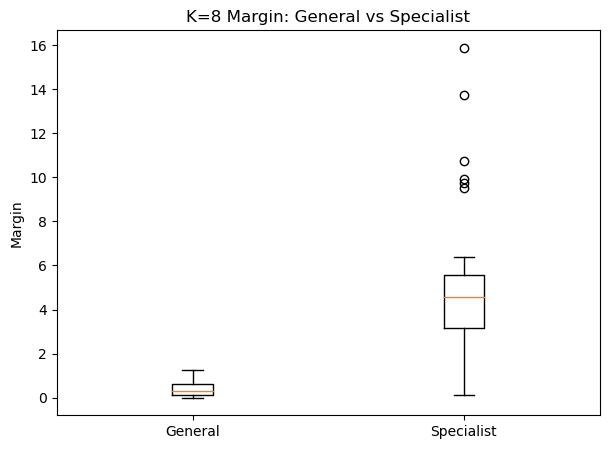

In [42]:
import matplotlib.pyplot as plt

general = df_k8.loc[df_k8["binary_expected"] == "general", "margin"]
specialist = df_k8.loc[df_k8["binary_expected"] == "specialist", "margin"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [general, specialist],
    labels=["General", "Specialist"]
)

plt.ylabel("Margin")
plt.title("K=8 Margin: General vs Specialist")
plt.show()

In [43]:
# df_k8[
#     (df_k8["binary_expected"] == "specialist")
#     & (df_k8["margin"] < 1.25)
# ][
#     [
#         "query_id",
#         "expected_service",
#         "predicted_label",
#         "max_score",
#         "margin",
#         "top_zscore"
#     ]
# ].sort_values("margin")

In [44]:
# df_k8.loc[
#     df_k8["query_id"].isin([33, 34]),
#     [
#         "query",
#         "expected_service",
#         "predicted_label",
#         "max_score",
#         "margin",
#         "top_zscore"
#     ]
# ]

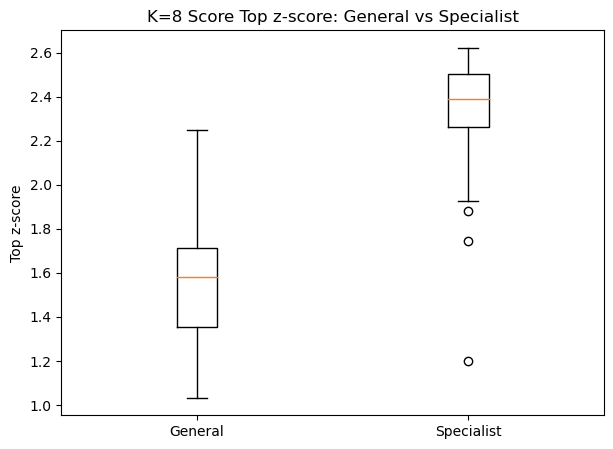

In [45]:
import matplotlib.pyplot as plt

general = df_k8.loc[df_k8["binary_expected"] == "general", "top_zscore"]
specialist = df_k8.loc[df_k8["binary_expected"] == "specialist", "top_zscore"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [general, specialist],
    labels=["General", "Specialist"]
)

plt.ylabel("Top z-score")
plt.title("K=8 Score Top z-score: General vs Specialist")

plt.show()

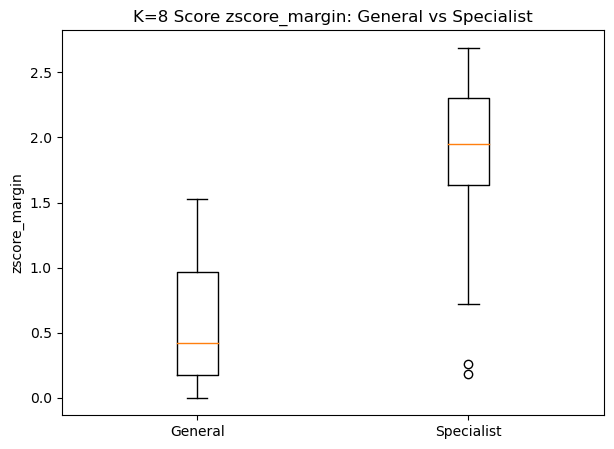

In [46]:
import matplotlib.pyplot as plt

general = df_k8.loc[df_k8["binary_expected"] == "general", "zscore_margin"]
specialist = df_k8.loc[df_k8["binary_expected"] == "specialist", "zscore_margin"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [general, specialist],
    labels=["General", "Specialist"]
)

plt.ylabel("zscore_margin")
plt.title("K=8 Score zscore_margin: General vs Specialist")

plt.show()

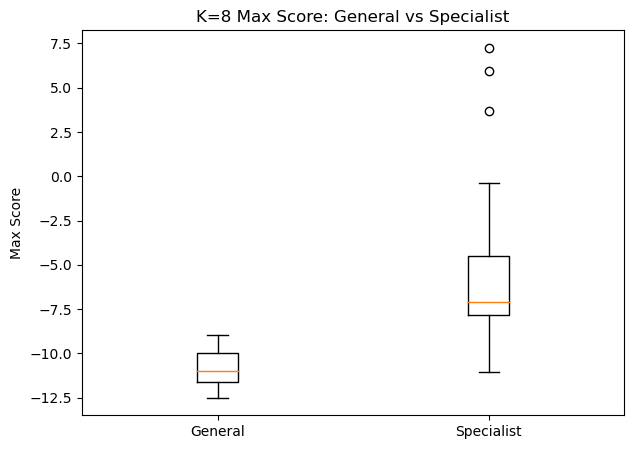

In [47]:
import matplotlib.pyplot as plt

general = df_k8.loc[df_k8["binary_expected"] == "general", "max_score"]
specialist = df_k8.loc[df_k8["binary_expected"] == "specialist", "max_score"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [general, specialist],
    labels=["General", "Specialist"]
)

plt.ylabel("Max Score")
plt.title("K=8 Max Score: General vs Specialist")

plt.show()

# K10

In [48]:
def get_binary_label(expected_service):
    if expected_service == "general":
        return "general"
    else:
        return "specialist"


df_k10["binary_expected"] = df_k10["expected_service"].apply(get_binary_label)

In [49]:
df_k10["binary_expected"].value_counts()

specialist    50
general       25
Name: binary_expected, dtype: int64

In [50]:
scores_k10 = pd.json_normalize(df_k10["scores"]).add_suffix("_score")
zscores_k10 = pd.json_normalize(df_k10["zscores"]).add_suffix("_zscore")

df_k10 = pd.concat(
    [
        df_k10.reset_index(drop=True),
        scores_k10.reset_index(drop=True),
        zscores_k10.reset_index(drop=True)
    ],
    axis=1
)

In [51]:
df_k10.columns.tolist()

['routing_method',
 'query',
 'raw_response',
 'predicted_label',
 'top_candidate',
 'model_name',
 'latency_ms',
 'prompt_tokens',
 'completion_tokens',
 'total_tokens',
 'max_score',
 'margin',
 'margin_ratio',
 'normalized_margin',
 'mean_score',
 'std_score',
 'top_zscore',
 'second_top_zscore',
 'zscore_margin',
 'scores',
 'zscores',
 'query_id',
 'expected_service',
 'is_correct',
 'error',
 'specialist_service_count',
 'total_service_count',
 'source_file',
 'binary_expected',
 'abstract_algebra_score',
 'anatomy_score',
 'astronomy_score',
 'business_ethics_score',
 'college_computer_science_score',
 'high_school_chemistry_score',
 'high_school_geography_score',
 'jurisprudence_score',
 'world_religions_score',
 'formal_logic_score',
 'abstract_algebra_zscore',
 'anatomy_zscore',
 'astronomy_zscore',
 'business_ethics_zscore',
 'college_computer_science_zscore',
 'high_school_chemistry_zscore',
 'high_school_geography_zscore',
 'jurisprudence_zscore',
 'world_religions_zscore'

In [52]:
df_k10[
    [
        "query_id",
        "expected_service",
        "binary_expected",
        "predicted_label",

        "max_score",
        "margin",

        "abstract_algebra_score",
        "anatomy_score",
        "astronomy_score",
        "business_ethics_score",
        "college_computer_science_score",
        "high_school_chemistry_score",
        "high_school_geography_score",
        "jurisprudence_score",
        "world_religions_score",
        "formal_logic_score",

        "top_zscore",

        "abstract_algebra_zscore",
        "anatomy_zscore",
        "astronomy_zscore",
        "business_ethics_zscore",
        "college_computer_science_zscore",
        "high_school_chemistry_zscore",
        "high_school_geography_zscore",
        "jurisprudence_zscore",
        "world_religions_zscore",
        "formal_logic_zscore",
    ]
]

,query_id,expected_service,binary_expected,predicted_label,max_score,margin,abstract_algebra_score,anatomy_score,astronomy_score,business_ethics_score,...,abstract_algebra_zscore,anatomy_zscore,astronomy_zscore,business_ethics_zscore,college_computer_science_zscore,high_school_chemistry_zscore,high_school_geography_zscore,jurisprudence_zscore,world_religions_zscore,formal_logic_zscore
0,0,abstract_algebra,specialist,abstract_algebra,-4.4375,6.2500,-4.4375,-12.87500,-12.68750,-14.37500,...,2.7109,-0.3465,-0.2786,-0.8901,0.4462,-0.1200,-1.0033,-0.3918,-0.4371,0.3103
1,1,abstract_algebra,specialist,abstract_algebra,7.2500,11.1250,7.2500,-11.43750,-12.31250,-12.75000,...,2.6995,-0.4133,-0.5590,-0.6319,0.0552,-0.3612,-0.7881,-0.4341,-0.4133,0.8464
2,2,abstract_algebra,specialist,abstract_algebra,6.1250,10.5625,6.1250,-11.18750,-11.62500,-12.62500,...,2.6802,-0.4235,-0.5020,-0.6813,0.1703,-0.3451,-0.9054,-0.5132,-0.2667,0.7866
3,3,abstract_algebra,specialist,abstract_algebra,3.6250,6.0000,3.6250,-9.62500,-11.25000,-12.31250,...,2.3777,-0.2697,-0.5944,-0.8067,0.4046,-0.4571,-1.1189,-0.3696,-0.3447,1.1789
4,4,abstract_algebra,specialist,abstract_algebra,-4.7500,5.2500,-4.7500,-12.75000,-13.37500,-14.81250,...,2.6235,-0.2442,-0.4682,-0.9835,0.7416,-0.1994,-0.9611,-0.3114,-0.4458,0.2487
5,5,anatomy,specialist,anatomy,-5.5625,5.8125,-13.0000,-5.56250,-11.37500,-13.93750,...,-0.3374,2.8743,0.3644,-0.7422,-0.3104,-0.0405,-0.5803,-0.4183,-0.3644,-0.4453
6,6,anatomy,specialist,anatomy,-6.2500,6.2500,-13.8750,-6.25000,-13.50000,-13.93750,...,-0.4005,2.9458,-0.2359,-0.4279,-0.4279,0.2030,-0.3730,-0.3456,-0.4553,-0.4827
7,7,anatomy,specialist,anatomy,-6.0000,5.3125,-11.3125,-6.00000,-11.62500,-13.00000,...,0.2204,2.8585,0.0652,-0.6176,-0.0900,-0.2762,-0.8349,-0.4935,-0.3073,-0.5245
8,8,anatomy,specialist,anatomy,-8.1250,3.5625,-11.6875,-8.12500,-12.25000,-14.12500,...,0.3301,2.7120,-0.0460,-1.2996,-0.1295,-0.2549,-0.7563,-0.2131,-0.3803,0.0376
9,9,anatomy,specialist,anatomy,-7.1562,4.9062,-13.5625,-7.15625,-12.37500,-14.25000,...,-0.3265,2.8156,0.2560,-0.6637,-0.3571,0.4092,-0.4491,-0.5410,-0.4797,-0.6637


In [53]:
df_k10.groupby("binary_expected")[["margin"]].describe()

margin                                                         \
                 count      mean       std     min       25%      50%     75%   
binary_expected                                                                 
general           25.0  0.400000  0.308305  0.0000  0.187500  0.31250  0.6875   
specialist        50.0  4.566252  2.731710  0.2188  2.515625  4.10935  6.1875   

                          
                     max  
binary_expected           
general           1.1875  
specialist       11.1250

In [54]:
df_k10.groupby("binary_expected")[["max_score"]].describe()

max_score                                                  \
                    count       mean       std     min       25%      50%   
binary_expected                                                             
general              25.0 -10.790000  0.963676 -12.500 -11.56250 -10.8750   
specialist           50.0  -5.358122  4.219460 -11.375  -7.97655  -7.0625   

                                  
                       75%   max  
binary_expected                   
general         -10.000000 -9.00  
specialist       -3.921875  7.25

In [55]:
df_k10.groupby("binary_expected")[["top_zscore"]].describe()

top_zscore                                               \
                     count      mean      std     min      25%      50%   
binary_expected                                                           
general               25.0  1.705104  0.28173  1.1959  1.51020  1.72230   
specialist            50.0  2.593254  0.26247  1.8115  2.50685  2.66385   

                                  
                     75%     max  
binary_expected                   
general          1.83220  2.3729  
specialist       2.77405  2.9458

In [56]:
df_k10.groupby("binary_expected")[["zscore_margin"]].describe()

zscore_margin                                                \
                        count      mean       std     min       25%     50%   
binary_expected                                                               
general                  25.0  0.579884  0.432455  0.0000  0.212300  0.4650   
specialist               50.0  1.929810  0.650576  0.1319  1.703225  2.0771   

                                   
                      75%     max  
binary_expected                    
general          0.909000  1.4982  
specialist       2.392925  2.9042

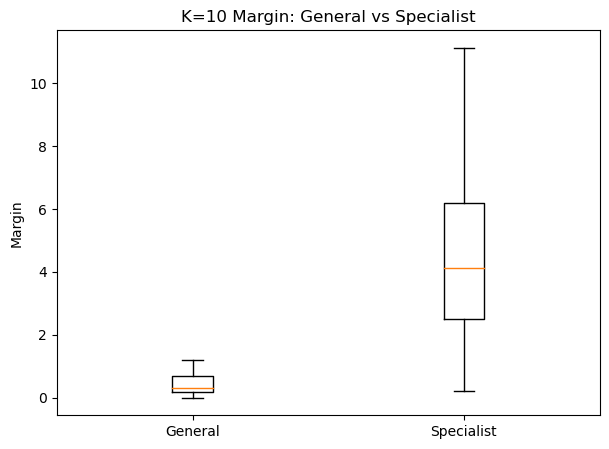

In [57]:
import matplotlib.pyplot as plt

general = df_k10.loc[df_k10["binary_expected"] == "general", "margin"]
specialist = df_k10.loc[df_k10["binary_expected"] == "specialist", "margin"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [general, specialist],
    labels=["General", "Specialist"]
)

plt.ylabel("Margin")
plt.title("K=10 Margin: General vs Specialist")
plt.show()

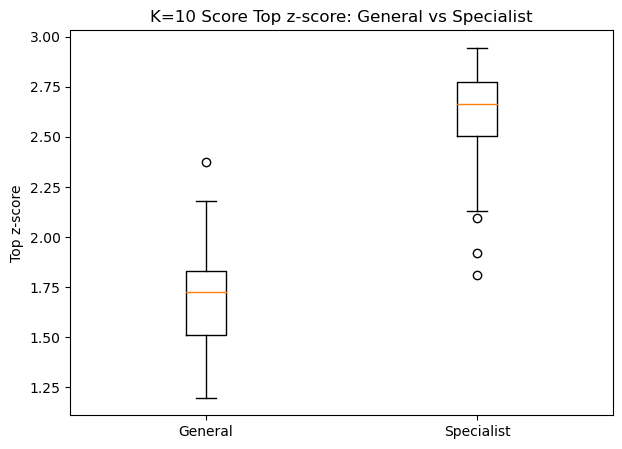

In [58]:
import matplotlib.pyplot as plt

general = df_k10.loc[df_k10["binary_expected"] == "general", "top_zscore"]
specialist = df_k10.loc[df_k10["binary_expected"] == "specialist", "top_zscore"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [general, specialist],
    labels=["General", "Specialist"]
)

plt.ylabel("Top z-score")
plt.title("K=10 Score Top z-score: General vs Specialist")

plt.show()

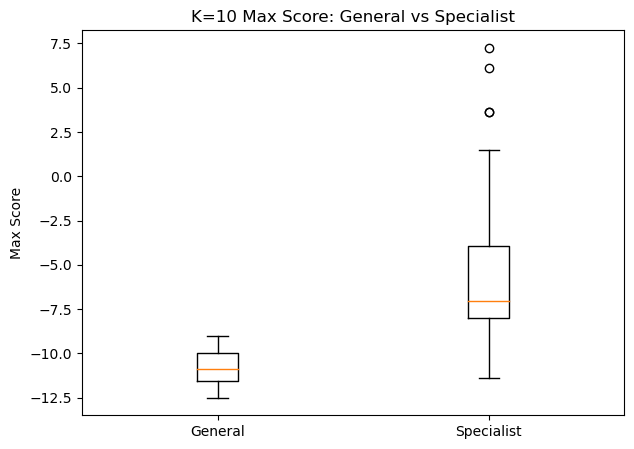

In [59]:
import matplotlib.pyplot as plt

general = df_k10.loc[df_k10["binary_expected"] == "general", "max_score"]
specialist = df_k10.loc[df_k10["binary_expected"] == "specialist", "max_score"]

plt.figure(figsize=(7, 5))

plt.boxplot(
    [general, specialist],
    labels=["General", "Specialist"]
)

plt.ylabel("Max Score")
plt.title("K=10 Max Score: General vs Specialist")

plt.show()

In [60]:
pd.set_option("display.max_colwidth", None)

In [61]:
# df_k10[
#     (
#         (df_k10["binary_expected"] == "specialist")
#         &
#         (df_k10["margin"] < 1.5)
#     )
# ][
#     [
#         "query",
#         "expected_service",
#         "predicted_label",
#         "max_score",
#         "margin",
#         "top_zscore"
#     ]
# ].sort_values("margin")

In [65]:
comparison = {
    "K": [3, 5, 8, 10],

    "margin": [
        df_k3[df_k3.binary_expected=="specialist"]["margin"].median(),
        df_k5[df_k5.binary_expected=="specialist"]["margin"].median(),
        df_k8[df_k8.binary_expected=="specialist"]["margin"].median(),
        df_k10[df_k10.binary_expected=="specialist"]["margin"].median(),
    ],

    "top_zscore": [
        df_k3[df_k3.binary_expected=="specialist"]["top_zscore"].median(),
        df_k5[df_k5.binary_expected=="specialist"]["top_zscore"].median(),
        df_k8[df_k8.binary_expected=="specialist"]["top_zscore"].median(),
        df_k10[df_k10.binary_expected=="specialist"]["top_zscore"].median(),
    ],

    "zscore_margin": [
        df_k3[df_k3.binary_expected=="specialist"]["zscore_margin"].median(),
        df_k5[df_k5.binary_expected=="specialist"]["zscore_margin"].median(),
        df_k8[df_k8.binary_expected=="specialist"]["zscore_margin"].median(),
        df_k10[df_k10.binary_expected=="specialist"]["zscore_margin"].median(),
    ],
}

comparison_df = pd.DataFrame(comparison)

comparison_df

,K,margin,top_zscore,zscore_margin
0,3,5.43750,1.40670,1.9837
1,5,5.28120,1.92840,1.9879
2,8,4.56250,2.39090,1.9524
3,10,4.10935,2.66385,2.0771


In [69]:
import pandas as pd

stability_df = pd.DataFrame({
    "K": [3, 5, 8, 10],

    "Q25": [
        df_k3[df_k3.binary_expected=="specialist"]["zscore_margin"].quantile(0.25),
        df_k5[df_k5.binary_expected=="specialist"]["zscore_margin"].quantile(0.25),
        df_k8[df_k8.binary_expected=="specialist"]["zscore_margin"].quantile(0.25),
        df_k10[df_k10.binary_expected=="specialist"]["zscore_margin"].quantile(0.25),
    ],

    "Median": [
        df_k3[df_k3.binary_expected=="specialist"]["zscore_margin"].median(),
        df_k5[df_k5.binary_expected=="specialist"]["zscore_margin"].median(),
        df_k8[df_k8.binary_expected=="specialist"]["zscore_margin"].median(),
        df_k10[df_k10.binary_expected=="specialist"]["zscore_margin"].median(),
    ],

    "Q75": [
        df_k3[df_k3.binary_expected=="specialist"]["zscore_margin"].quantile(0.75),
        df_k5[df_k5.binary_expected=="specialist"]["zscore_margin"].quantile(0.75),
        df_k8[df_k8.binary_expected=="specialist"]["zscore_margin"].quantile(0.75),
        df_k10[df_k10.binary_expected=="specialist"]["zscore_margin"].quantile(0.75),
    ],
})

stability_df = stability_df.round(4)

stability_df

,K,Q25,Median,Q75
0,3,1.8855,1.9837,2.0761
1,5,1.7966,1.9879,2.1260
2,8,1.6380,1.9524,2.2998
3,10,1.7032,2.0771,2.3929


In [70]:
import pandas as pd

stability_df = pd.DataFrame({
    "K": [3, 5, 8, 10],

    "Q25": [
        df_k3[df_k3.binary_expected=="specialist"]["margin"].quantile(0.25),
        df_k5[df_k5.binary_expected=="specialist"]["margin"].quantile(0.25),
        df_k8[df_k8.binary_expected=="specialist"]["margin"].quantile(0.25),
        df_k10[df_k10.binary_expected=="specialist"]["margin"].quantile(0.25),
    ],

    "Median": [
        df_k3[df_k3.binary_expected=="specialist"]["margin"].median(),
        df_k5[df_k5.binary_expected=="specialist"]["margin"].median(),
        df_k8[df_k8.binary_expected=="specialist"]["margin"].median(),
        df_k10[df_k10.binary_expected=="specialist"]["margin"].median(),
    ],

    "Q75": [
        df_k3[df_k3.binary_expected=="specialist"]["margin"].quantile(0.75),
        df_k5[df_k5.binary_expected=="specialist"]["margin"].quantile(0.75),
        df_k8[df_k8.binary_expected=="specialist"]["margin"].quantile(0.75),
        df_k10[df_k10.binary_expected=="specialist"]["margin"].quantile(0.75),
    ],
})

stability_df = stability_df.round(4)

stability_df

,K,Q25,Median,Q75
0,3,4.8906,5.4375,8.1250
1,5,4.0000,5.2812,6.3125
2,8,3.1562,4.5625,5.5547
3,10,2.5156,4.1094,6.1875


In [73]:
import pandas as pd

stability_df = pd.DataFrame({
    "K": [3, 5, 8, 10],

    "Q25": [
        df_k3[df_k3.binary_expected=="specialist"]["top_zscore"].quantile(0.25),
        df_k5[df_k5.binary_expected=="specialist"]["top_zscore"].quantile(0.25),
        df_k8[df_k8.binary_expected=="specialist"]["top_zscore"].quantile(0.25),
        df_k10[df_k10.binary_expected=="specialist"]["top_zscore"].quantile(0.25),
    ],

    "Median": [
        df_k3[df_k3.binary_expected=="specialist"]["top_zscore"].median(),
        df_k5[df_k5.binary_expected=="specialist"]["top_zscore"].median(),
        df_k8[df_k8.binary_expected=="specialist"]["top_zscore"].median(),
        df_k10[df_k10.binary_expected=="specialist"]["top_zscore"].median(),
    ],

    "Q75": [
        df_k3[df_k3.binary_expected=="specialist"]["top_zscore"].quantile(0.75),
        df_k5[df_k5.binary_expected=="specialist"]["top_zscore"].quantile(0.75),
        df_k8[df_k8.binary_expected=="specialist"]["top_zscore"].quantile(0.75),
        df_k10[df_k10.binary_expected=="specialist"]["top_zscore"].quantile(0.75),
    ],
})

stability_df = stability_df.round(4)

stability_df

,K,Q25,Median,Q75
0,3,1.3941,1.4067,1.4133
1,5,1.8092,1.9284,1.9636
2,8,2.2645,2.3909,2.5041
3,10,2.5068,2.6638,2.7740


In [67]:
comparison_binary = pd.DataFrame({

    "K": [3, 5, 8, 10],

    "general_median": [
        df_k3[df_k3.binary_expected=="general"]["zscore_margin"].median(),
        df_k5[df_k5.binary_expected=="general"]["zscore_margin"].median(),
        df_k8[df_k8.binary_expected=="general"]["zscore_margin"].median(),
        df_k10[df_k10.binary_expected=="general"]["zscore_margin"].median(),
    ],

    "specialist_median": [
        df_k3[df_k3.binary_expected=="specialist"]["zscore_margin"].median(),
        df_k5[df_k5.binary_expected=="specialist"]["zscore_margin"].median(),
        df_k8[df_k8.binary_expected=="specialist"]["zscore_margin"].median(),
        df_k10[df_k10.binary_expected=="specialist"]["zscore_margin"].median(),
    ],

})

comparison_binary.round(4)

,K,general_median,specialist_median
0,3,1.6036,0.8870
1,5,0.5812,0.7225
2,8,0.4207,0.5769
3,10,0.4650,0.5750


In [3]:
all_rows = []

for k, folder_name in folders.items():

    folder_path = os.path.join(base_path, folder_name)

    for file_name in os.listdir(folder_path):

        if not file_name.endswith(".json"):
            continue
            
        if "_efficiency" in file_name:
            continue

        file_path = os.path.join(folder_path, file_name)

        with open(file_path, "r") as f:
            data = json.load(f)

        for row in data:
            row["source_file"] = file_name
            all_rows.append(row)

In [4]:
df = pd.DataFrame(all_rows)

In [5]:
confidence_df = pd.json_normalize(df["confidence"])

confidence_df = confidence_df.rename(
    columns={"max": "max_score"}
)

df = pd.concat([df, confidence_df], axis=1)

In [6]:
df

,routing_method,query,raw_response,predicted_label,model_name,latency_ms,prompt_tokens,completion_tokens,total_tokens,scores,...,expected_service,is_correct,error,specialist_service_count,total_service_count,source_file,k,max_score,margin,std
0,cross-encoder,Find all c in Z_3 such that Z_3[x]/(x^2 + c) i...,None,abstract_algebra,Qwen/Qwen3-Reranker-4B,409.794751,266,0,266,"{'abstract_algebra': -4.375, 'anatomy': -12.87...",...,abstract_algebra,True,None,3,3,cross-encoder_Qwen-Qwen3-Reranker-4B.json,3,-4.3750,8.3125,3.9635
1,cross-encoder,Statement 1 | If aH is an element of a factor ...,None,abstract_algebra,Qwen/Qwen3-Reranker-4B,46.805847,326,0,326,"{'abstract_algebra': 7.25, 'anatomy': -11.5625...",...,abstract_algebra,True,None,3,3,cross-encoder_Qwen-Qwen3-Reranker-4B.json,3,7.2500,18.8125,9.0192
2,cross-encoder,Statement 1 | Every element of a group generat...,None,abstract_algebra,Qwen/Qwen3-Reranker-4B,45.844679,293,0,293,"{'abstract_algebra': 5.9375, 'anatomy': -11.12...",...,abstract_algebra,True,None,3,3,cross-encoder_Qwen-Qwen3-Reranker-4B.json,3,5.9375,17.0625,8.1332
3,cross-encoder,Statement 1| Every function from a finite set ...,None,abstract_algebra,Qwen/Qwen3-Reranker-4B,45.773243,290,0,290,"{'abstract_algebra': 3.6875, 'anatomy': -9.562...",...,abstract_algebra,True,None,3,3,cross-encoder_Qwen-Qwen3-Reranker-4B.json,3,3.6875,13.2500,6.6795
4,cross-encoder,Find the characteristic of the ring 2Z.,None,abstract_algebra,Qwen/Qwen3-Reranker-4B,44.889348,221,0,221,"{'abstract_algebra': -4.75, 'anatomy': -12.687...",...,abstract_algebra,True,None,3,3,cross-encoder_Qwen-Qwen3-Reranker-4B.json,3,-4.7500,7.9375,3.8974
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
225,cross-encoder,What is the sign of the covenant for Jewish m...,None,world_religions,Qwen/Qwen3-Reranker-4B,102.985758,704,0,704,"{'abstract_algebra': -13.4375, 'anatomy': -11....",...,world_religions,True,None,10,10,cross-encoder_Qwen-Qwen3-Reranker-4B.json,10,-11.3750,0.5000,0.6459
226,cross-encoder,What is the Second Gem in Buddhism?,None,world_religions,Qwen/Qwen3-Reranker-4B,101.864317,674,0,674,"{'abstract_algebra': -12.125, 'anatomy': -11.4...",...,world_religions,True,None,10,10,cross-encoder_Qwen-Qwen3-Reranker-4B.json,10,-7.8125,3.6250,1.4620
227,cross-encoder,"In which dynasty was the ""Mandate of Heaven"" ...",None,world_religions,Qwen/Qwen3-Reranker-4B,104.886513,804,0,804,"{'abstract_algebra': -13.75, 'anatomy': -13.12...",...,world_religions,True,None,10,10,cross-encoder_Qwen-Qwen3-Reranker-4B.json,10,-10.1250,1.4375,1.0492
228,cross-encoder,Which Japanese government promoted a kind of ...,None,world_religions,Qwen/Qwen3-Reranker-4B,104.532194,784,0,784,"{'abstract_algebra': -13.8125, 'anatomy': -13....",...,world_religions,True,None,10,10,cross-encoder_Qwen-Qwen3-Reranker-4B.json,10,-10.0000,2.4375,1.0984


In [7]:
df_k3 = df[df["k"] == 3].copy()
df_k3 = df_k3.reset_index(drop=True)

scores_k3 = pd.json_normalize(df_k3["scores"])

df_k3 = pd.concat([df_k3, scores_k3], axis=1)

In [8]:
df_k3[
    [
        "query",
        "expected_service",
        "predicted_label",
        "max_score",
        "margin",
        "std",
        "abstract_algebra",
        "anatomy",
        "astronomy"
    ]
]

,query,expected_service,predicted_label,max_score,margin,std,abstract_algebra,anatomy,astronomy
0,Find all c in Z_3 such that Z_3[x]/(x^2 + c) i...,abstract_algebra,abstract_algebra,-4.3750,8.3125,3.9635,-4.3750,-12.87500,-12.68750
1,Statement 1 | If aH is an element of a factor ...,abstract_algebra,abstract_algebra,7.2500,18.8125,9.0192,7.2500,-11.56250,-12.18750
2,Statement 1 | Every element of a group generat...,abstract_algebra,abstract_algebra,5.9375,17.0625,8.1332,5.9375,-11.12500,-11.50000
3,Statement 1| Every function from a finite set ...,abstract_algebra,abstract_algebra,3.6875,13.2500,6.6795,3.6875,-9.56250,-11.25000
4,Find the characteristic of the ring 2Z.,abstract_algebra,abstract_algebra,-4.7500,7.9375,3.8974,-4.7500,-12.68750,-13.31250
5,What is the embryological origin of the hyoid ...,anatomy,anatomy,-5.5000,5.8125,3.2125,-13.0000,-5.50000,-11.31250
6,Which of these branches of the trigeminal nerv...,anatomy,anatomy,-6.1875,7.3125,3.5388,-13.8750,-6.18750,-13.50000
7,The pleura,anatomy,anatomy,-6.1562,5.1562,2.4455,-11.3125,-6.15625,-11.37500
8,In Angle's Class II Div 2 occlusion there is,anatomy,anatomy,-8.1250,3.5000,1.7795,-11.6250,-8.12500,-12.12500
9,Which of the following is the body cavity that...,anatomy,anatomy,-7.0938,5.4062,2.8324,-13.5625,-7.09375,-12.50000


In [9]:
df_k10 = df[df["k"] == 10].copy()
df_k10 = df_k10.reset_index(drop=True)

scores_k10 = pd.json_normalize(df_k10["scores"])

df_k10 = pd.concat([df_k10, scores_k10], axis=1)

In [10]:
df_k10[
    [
        "query",
        "expected_service",
        "predicted_label",
        "max_score",
        "margin",
        "std",
        "abstract_algebra",
        "anatomy",
        "astronomy",
        "business_ethics",
        "college_computer_science",
        "formal_logic",
        "high_school_chemistry",
        "high_school_geography",
        "jurisprudence",
        "world_religions"
        
        
    ]
]

,query,expected_service,predicted_label,max_score,margin,std,abstract_algebra,anatomy,astronomy,business_ethics,college_computer_science,formal_logic,high_school_chemistry,high_school_geography,jurisprudence,world_religions
0,Find all c in Z_3 such that Z_3[x]/(x^2 + c) i...,abstract_algebra,abstract_algebra,-4.4375,6.2500,2.7596,-4.4375,-12.8750,-12.6875,-14.3750,-10.6875,-11.0625,-12.2500,-14.6875,-13.0000,-13.1250
1,Statement 1 | If aH is an element of a factor ...,abstract_algebra,abstract_algebra,7.2500,11.1250,6.0035,7.2500,-11.4375,-12.3125,-12.7500,-8.6250,-3.8750,-11.1250,-13.6875,-11.5625,-11.4375
2,Statement 1 | Every element of a group generat...,abstract_algebra,abstract_algebra,6.1250,10.5625,5.5779,6.1250,-11.1875,-11.6250,-12.6250,-7.8750,-4.4375,-10.7500,-13.8750,-11.6875,-10.3125
3,Statement 1| Every function from a finite set ...,abstract_algebra,abstract_algebra,3.6250,6.0000,5.0049,3.6250,-9.6250,-11.2500,-12.3125,-6.2500,-2.3750,-10.5625,-13.8750,-10.1250,-10.0000
4,Find the characteristic of the ring 2Z.,abstract_algebra,abstract_algebra,-4.7500,5.2500,2.7897,-4.7500,-12.7500,-13.3750,-14.8125,-10.0000,-11.3750,-12.6250,-14.7500,-12.9375,-13.3125
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,What is the sign of the covenant for Jewish m...,world_religions,world_religions,-11.3750,0.5000,0.6459,-13.4375,-11.8750,-13.0000,-13.5625,-12.8750,-13.0000,-12.6250,-13.1875,-12.5625,-11.3750
71,What is the Second Gem in Buddhism?,world_religions,world_religions,-7.8125,3.6250,1.4620,-12.1250,-11.4375,-11.4375,-12.9375,-11.9375,-12.7500,-12.6875,-13.2500,-11.8750,-7.8125
72,"In which dynasty was the ""Mandate of Heaven"" ...",world_religions,world_religions,-10.1250,1.4375,1.0492,-13.7500,-13.1250,-13.1250,-13.3750,-13.3750,-13.3125,-13.3125,-12.6250,-11.5625,-10.1250
73,Which Japanese government promoted a kind of ...,world_religions,world_religions,-10.0000,2.4375,1.0984,-13.8125,-13.3750,-12.8750,-13.7500,-13.3750,-14.0000,-13.3750,-12.4375,-12.6875,-10.0000


In [11]:
def get_binary_label(expected_service):
    if expected_service == "general":
        return "general"
    else:
        return "specialist"


df["binary_expected"] = df["expected_service"].apply(get_binary_label)

In [15]:
df[
    [
        "expected_service",
        "binary_expected",
        "k",
        "max_score",
        "margin",
        "std"
    ]
].head(10)

,expected_service,binary_expected,k,max_score,margin,std
0,abstract_algebra,specialist,3,-4.3750,8.3125,3.9635
1,abstract_algebra,specialist,3,7.2500,18.8125,9.0192
2,abstract_algebra,specialist,3,5.9375,17.0625,8.1332
3,abstract_algebra,specialist,3,3.6875,13.2500,6.6795
4,abstract_algebra,specialist,3,-4.7500,7.9375,3.8974
5,anatomy,specialist,3,-5.5000,5.8125,3.2125
6,anatomy,specialist,3,-6.1875,7.3125,3.5388
7,anatomy,specialist,3,-6.1562,5.1562,2.4455
8,anatomy,specialist,3,-8.1250,3.5000,1.7795
9,anatomy,specialist,3,-7.0938,5.4062,2.8324


In [17]:
summary = df.groupby(["k", "binary_expected"])[["max_score", "margin", "std"]].agg(["count", "mean", "median", "min", "max"])
summary

max_score                                     margin  \
                       count       mean   median      min    max  count   
k  binary_expected                                                        
3  general                25 -11.445000 -11.4375 -15.0625 -8.375     25   
   specialist             15  -4.120833  -6.1562  -8.2500  7.250     15   
5  general                25 -11.085000 -11.1875 -14.5625 -8.125     25   
   specialist             25  -5.122508  -6.8750  -8.3125  7.125     25   
8  general                25 -10.218748 -10.5625 -13.8125 -1.375     25   
   specialist             40  -5.596090  -7.0938 -11.0625  7.250     40   
10 general                25  -9.958752 -10.5000 -12.1250 -1.375     25   
   specialist             50  -5.358122  -7.0625 -11.3750  7.250     50   

                                                         std            \
                        mean   median     min      max count      mean   
k  binary_expected                                                       
3  general          0.835000  0.62500  0.0000   2.6250    25  0.628628   
   specialist       7.754160  5.43750  3.5000  18.8125    15  3.868807   
5  general          0.787500  0.56250  0.1250   2.7500    25  0.765884   
   specialist       5.951240  5.28120  2.2812  15.7500    25  3.030748   
8  general          1.266248  0.75000  0.0000   5.6250    25  0.991128   
   specialist       4.953127  4.56250  0.1250  15.8750    40  2.467288   
10 general          1.225004  0.68750  0.0625   5.7188    25  1.015508   
   specialist       4.566252  4.10935  0.2188  11.1250    50  2.337576   

                                             
                     median     min     max  
k  binary_expected                           
3  general          0.46770  0.1792  1.4669  
   specialist       2.87870  1.7795  9.0192  
5  general          0.71850  0.1837  1.7016  
   specialist       2.56490  1.5491  7.5292  
8  general          0.79790  0.2669  2.6669  
   specialist       2.20205  0.4754  6.4034  
10 general          0.96640  0.2982  2.3701  
   specialist       2.05045  0.6459  6.0035

In [18]:
def get_binary_target(label):
    if label == "specialist":
        return 1
    else:
        return 0


df["binary_target"] = df["binary_expected"].apply(get_binary_target)

In [19]:
df_k10 = df[df["k"] == 10]

In [20]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(
    df_k10["binary_target"],
    df_k10["max_score"]
)

auc = roc_auc_score(
    df_k10["binary_target"],
    df_k10["max_score"]
)

print("AUC:", auc)

AUC: 0.8952


In [21]:
roc_df = pd.DataFrame({
    "threshold": thresholds,
    "true_positive_rate": tpr,
    "false_positive_rate": fpr
})

roc_df

,threshold,true_positive_rate,false_positive_rate
0,8.2500,0.00,0.00
1,7.2500,0.02,0.00
2,6.1250,0.04,0.00
3,3.6250,0.08,0.00
4,-1.1875,0.16,0.00
5,-1.3750,0.16,0.04
6,-2.3125,0.20,0.04
7,-2.5000,0.24,0.04
8,-3.7500,0.26,0.04
9,-4.4375,0.30,0.04


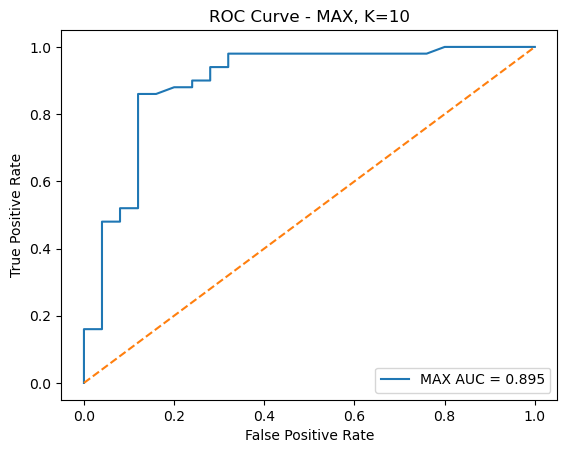

In [22]:
import matplotlib.pyplot as plt

plt.plot(fpr, tpr, label=f"MAX AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - MAX, K=10")
plt.legend()

plt.show()

In [23]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

df_k10 = df[df["k"] == 10]

# MAX
fpr_max, tpr_max, thresholds_max = roc_curve(
    df_k10["binary_target"],
    df_k10["max_score"]
)

auc_max = roc_auc_score(
    df_k10["binary_target"],
    df_k10["max_score"]
)

# Margin
fpr_margin, tpr_margin, thresholds_margin = roc_curve(
    df_k10["binary_target"],
    df_k10["margin"]
)

auc_margin = roc_auc_score(
    df_k10["binary_target"],
    df_k10["margin"]
)

# STD
fpr_std, tpr_std, thresholds_std = roc_curve(
    df_k10["binary_target"],
    df_k10["std"]
)

auc_std = roc_auc_score(
    df_k10["binary_target"],
    df_k10["std"]
)

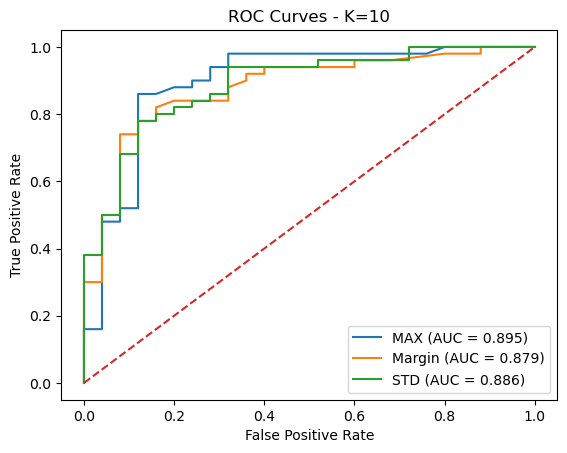

In [24]:
plt.plot(
    fpr_max,
    tpr_max,
    label=f"MAX (AUC = {auc_max:.3f})"
)

plt.plot(
    fpr_margin,
    tpr_margin,
    label=f"Margin (AUC = {auc_margin:.3f})"
)

plt.plot(
    fpr_std,
    tpr_std,
    label=f"STD (AUC = {auc_std:.3f})"
)

plt.plot([0, 1], [0, 1], "--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - K=10")
plt.legend()

plt.show()

In [27]:
from sklearn.metrics import roc_curve, roc_auc_score

df_k10 = df[df["k"] == 10]

fpr, tpr, thresholds = roc_curve(
    df_k10["binary_target"],
    df_k10["margin"]
)

margin_auc = roc_auc_score(
    df_k10["binary_target"],
    df_k10["margin"]
)

margin_roc = pd.DataFrame({
    "threshold": thresholds,
    "TPR": tpr,
    "FPR": fpr
})

margin_roc

,threshold,TPR,FPR
0,12.1250,0.00,0.00
1,11.1250,0.02,0.00
2,6.6875,0.18,0.00
3,6.2500,0.26,0.00
4,5.8125,0.30,0.00
5,5.7188,0.30,0.04
6,5.2500,0.38,0.04
7,4.3125,0.50,0.04
8,4.2188,0.50,0.08
9,2.7500,0.74,0.08


In [29]:
df_k10 = df[df["k"] == 10].copy()

targets = [0.10, 0.20, 0.25, 0.30, 0.40, 0.50]

In [30]:
for target in targets:

    threshold = df_k10["margin"].quantile(target)

    print(
        "Target fallback:",
        target,
        "Margin threshold:",
        threshold
    )

Target fallback: 0.1 Margin threshold: 0.3125
Target fallback: 0.2 Margin threshold: 0.6625000000000001
Target fallback: 0.25 Margin threshold: 1.15625
Target fallback: 0.3 Margin threshold: 1.45
Target fallback: 0.4 Margin threshold: 2.0625000000000004
Target fallback: 0.5 Margin threshold: 2.9375


In [31]:
results = []

for target in targets:

    threshold = df_k10["margin"].quantile(target)

    predictions = []

    for margin in df_k10["margin"]:

        if margin > threshold:
            predictions.append("specialist")
        else:
            predictions.append("general")

    temp = df_k10.copy()
    temp["gate_prediction"] = predictions

    tp = (
        (temp["binary_expected"] == "specialist") &
        (temp["gate_prediction"] == "specialist")
    ).sum()

    fn = (
        (temp["binary_expected"] == "specialist") &
        (temp["gate_prediction"] == "general")
    ).sum()

    fp = (
        (temp["binary_expected"] == "general") &
        (temp["gate_prediction"] == "specialist")
    ).sum()

    tn = (
        (temp["binary_expected"] == "general") &
        (temp["gate_prediction"] == "general")
    ).sum()

    tpr = tp / (tp + fn)
    fpr = fp / (fp + tn)

    results.append({
        "target_fallback": target,
        "margin_threshold": threshold,
        "TPR": tpr,
        "FPR": fpr
    })

results_df = pd.DataFrame(results)

results_df

,target_fallback,margin_threshold,TPR,FPR
0,0.10,0.31250,0.96,0.68
1,0.20,0.66250,0.94,0.52
2,0.25,1.15625,0.92,0.40
3,0.30,1.45000,0.88,0.32
4,0.40,2.06250,0.82,0.16
5,0.50,2.93750,0.70,0.08


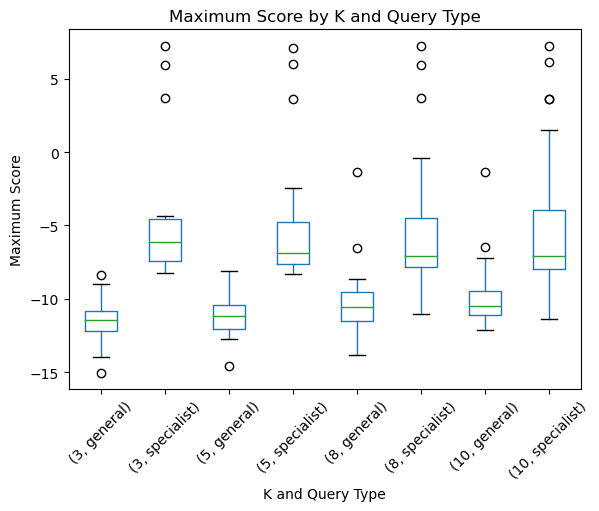

In [10]:
import matplotlib.pyplot as plt

df.boxplot(
    column="max_score",
    by=["k", "binary_expected"],
    grid=False
)

plt.title("Maximum Score by K and Query Type")
plt.suptitle("")
plt.xlabel("K and Query Type")
plt.ylabel("Maximum Score")
plt.xticks(rotation=45)
plt.show()

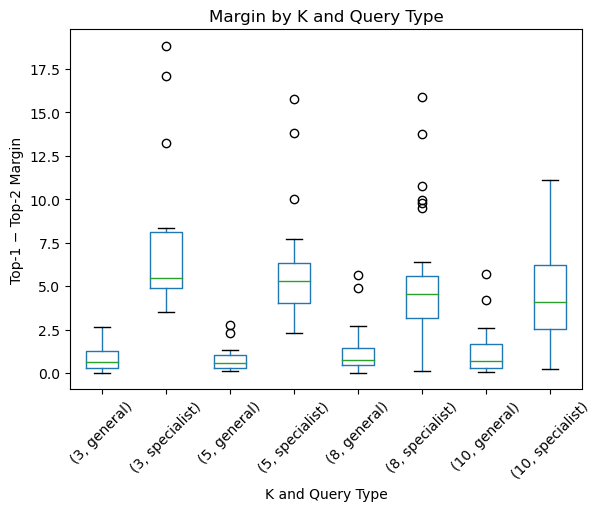

In [11]:
df.boxplot(
    column="margin",
    by=["k", "binary_expected"],
    grid=False
)

plt.title("Margin by K and Query Type")
plt.suptitle("")
plt.xlabel("K and Query Type")
plt.ylabel("Top-1 − Top-2 Margin")
plt.xticks(rotation=45)
plt.show()

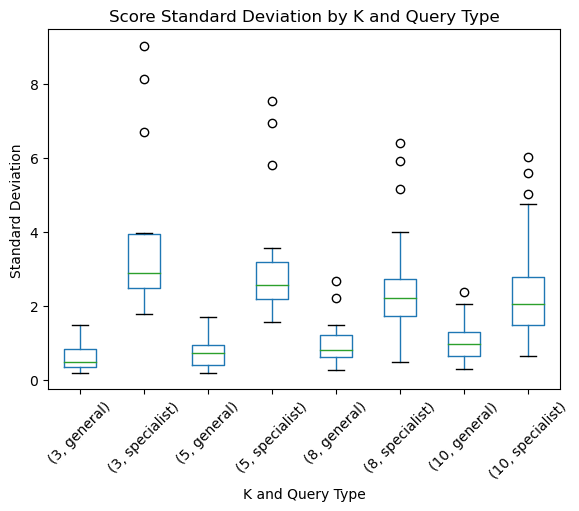

In [12]:
df.boxplot(
    column="std",
    by=["k", "binary_expected"],
    grid=False
)

plt.title("Score Standard Deviation by K and Query Type")
plt.suptitle("")
plt.xlabel("K and Query Type")
plt.ylabel("Standard Deviation")
plt.xticks(rotation=45)
plt.show()

In [13]:
def get_binary_target(label):
    if label == "specialist":
        return 1
    else:
        return 0


df["binary_target"] = df["binary_expected"].apply(get_binary_target)

In [14]:
from sklearn.metrics import roc_auc_score

results = []

for k in [3, 5, 8, 10]:

    df_k = df[df["k"] == k]

    max_auc = roc_auc_score(
        df_k["binary_target"],
        df_k["max_score"]
    )

    margin_auc = roc_auc_score(
        df_k["binary_target"],
        df_k["margin"]
    )

    std_auc = roc_auc_score(
        df_k["binary_target"],
        df_k["std"]
    )

    results.append({
        "k": k,
        "max_auc": max_auc,
        "margin_auc": margin_auc,
        "std_auc": std_auc
    })

auc_df = pd.DataFrame(results)

auc_df

,k,max_auc,margin_auc,std_auc
0,3,1.0000,1.0000,1.0000
1,5,0.9968,0.9968,0.9936
2,8,0.9150,0.8875,0.9040
3,10,0.8952,0.8788,0.8864
